# 05 · A template from the data: TIRAVEL

**What you'll learn**

- how TIRAVEL builds a template from the observations themselves, one function of
  `sparta.tiravel_ops` at a time: to rest, onto one grid, normalised, correlated, co-added
- the alignment measure ρ: why it peaks at the right velocities, and why noise keeps it below 1
- why only velocity *differences* matter
- on simulated data: the template is far less noisy than one epoch and gives RVs consistent
  with the truth
- on HARPS spectra of TOI-193: it reproduces a PHOENIX library template

Every step is a function call on plain arrays. The last cell runs the same builds with SPARTA's
objects and checks that they give the same numbers.

In [1]:
import pathlib

import numpy as np
import matplotlib.pyplot as plt

from sparta import instruments
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_spectra, simulate
from sparta.plotting import (EXTRA_COLOR, GREY, apply_style, map_colorbar, map_image,
                             plot_curve, plot_data, plot_extra, plot_model, plot_points)
from sparta.preprocess import (bandpass, coarsest_native_step, filtered_noise_fraction, remove_cosmics,
                               resample_to_linear_grid, resample_to_log_grid, trim_margins)
from sparta.template import phoenix_spectrum
from sparta.tiravel_ops import (align_spectra, alignment, build_tiravel, coadd, common_grid,
                                correlation_matrix, normalize_rows, rest_frame_wavelengths)
from unicor import (C_KMS, broaden_gaussian, broaden_rotational, ccf_order, combine_ccfs,
                    doppler_shift_wave, dv_from_wave, lag_axis, log_lambda_grid, measure_rv,
                    resample)

apply_style()

# Zero-mean, unit-variance copy, to compare shapes whatever the scale
def standardise(x):
    '''Zero mean, unit variance: compares shapes regardless of scale.'''
    return (x - x.mean()) / x.std()

# What is left of x once its best linear fit to the truth is removed
def residual(x, truth):
    '''x minus its best linear fit a + b * truth, divided by b: in units of the truth's flux.'''
    design = np.column_stack([np.ones_like(truth), truth])
    (a, b), *_ = np.linalg.lstsq(design, x, rcond=None)
    return (x - a - b * truth) / b

## 1. The idea

UNICOR and TODCOR need a template. When no library model fits the star well (peculiar,
active or fast-rotating stars), TIRAVEL (Zucker & Mazeh 2006) builds one from the data. Given
$K$ epochs and a trial velocity $v_k$ for each:

1. shift every spectrum back to rest and resample them onto one common grid
   (`rest_frame_wavelengths`, `common_grid`, `align_spectra`);
2. normalise each (zero mean, unit norm; `normalize_rows`);
3. form their $K \times K$ correlation matrix (`correlation_matrix`). If the velocities are right,
   all rows are the same spectrum plus noise, so its largest eigenvalue $\lambda_{\max}$
   approaches $K$ (reaching it only without noise). The alignment measure is
   $\rho = (\lambda_{\max} - 1)/(K - 1)$, between 0 and 1 (`alignment`);
4. co-add the epochs with the weights of the leading eigenvector: that is the template (`coadd`).

Units and assumptions of each function: [open API § TIRAVEL](../../docs/open_api.md#tiravel--a-template-from-the-observations-spartatiravel_ops).

## 2. Simulated data: the truth is known

30 epochs of a single-lined star observed "like HARPS" (5000-5100 Å), with photon noise at a
signal-to-noise of 50 per native pixel at the continuum (fixed seed). `simulate` returns one
record of plain arrays per epoch (one order, Å in air); `component_spectra` gives the noiseless
rest-frame spectrum the epochs were made from.

In [2]:
# Simulate 30 epochs of a single-lined star with known velocities and photon noise
SNR = 50
times = np.sort(np.random.default_rng(5).uniform(0, 30, 30))
rv_true = -8.0 + 25.0 * np.sin(2 * np.pi * times / 6.1)              # km/s
star = dict(teff=5800, logg=3.5, feh=0.5, vsini=3.0)

# One simulated data set (HARPS-like, 5000-5100 Å) at a given S/N
def simulation(snr):
    '''30 HARPS-like epochs of the star at signal-to-noise snr (None: noiseless).'''
    return Simulation(like="HARPS", windows_A=[(5000, 5100)], times=times, rv_kms=rv_true,
                      components=[star], snr=snr, noise="photon", seed=6)

# Wavelengths and fluxes of its epochs, as plain arrays
def epochs(snr):
    '''The simulated epochs' wavelengths (Å) and fluxes, one array per epoch.'''
    records, _ = simulate(simulation(snr))
    return [rec.wave[0] for rec in records], [rec.flux[0] for rec in records]

# The noisy epochs, and the noiseless rest-frame spectrum they came from
sim = simulation(SNR)
waves, fluxes = epochs(SNR)
truth_wave, truth_flux = component_spectra(sim)[0][0]                 # star 0, order 0
# How many epochs, and the native pixel size (km/s)
K = len(waves)
print(f"{K} epochs of {waves[0].size} native pixels ({dv_from_wave(waves[0]):.3f} km/s each)")

30 epochs of 9743 native pixels (0.609 km/s each)


**Step 1: to rest, onto one grid.** `rest_frame_wavelengths` divides the observed wavelengths by
$1 + v_k/c$. `common_grid` takes the rest-frame grid of epoch 0, clipped to the range every
de-shifted epoch covers minus a 10-pixel margin, so no epoch is extrapolated; `align_spectra`
resamples every epoch onto it (cubic). The two epochs of most different velocity:

epoch 0 at +5.54 km/s: 5000.000 Å observed is 4999.908 Å at rest
common grid 5000.65-5099.60 Å, 9641 pixels; aligned: (30, 9641)


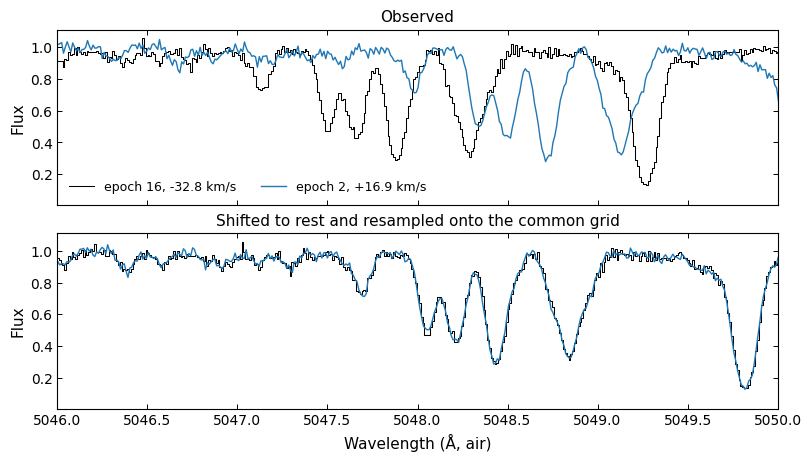

In [3]:
# Step 1: shift to rest, build the common grid, resample every epoch onto it
rest0 = rest_frame_wavelengths(waves[0], rv_true[0])
grid = common_grid(waves, rv_true, margin=10)
aligned = align_spectra(waves, fluxes, rv_true, grid)                  # (K, M): one row per epoch
# Check the shift and the grid size
print(f"epoch 0 at {rv_true[0]:+.2f} km/s: {waves[0][0]:.3f} Å observed is {rest0[0]:.3f} Å at rest")
print(f"common grid {grid[0]:.2f}-{grid[-1]:.2f} Å, {grid.size} pixels; aligned: {aligned.shape}")

# Plot the two epochs of most different velocity, before and after aligning
lo, hi = np.argmin(rv_true), np.argmax(rv_true)
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(8, 4.5))
plot_data(top, waves[lo], fluxes[lo], label=f"epoch {lo}, {rv_true[lo]:+.1f} km/s")
plot_extra(top, waves[hi], fluxes[hi], label=f"epoch {hi}, {rv_true[hi]:+.1f} km/s")
top.set_title("Observed")
top.legend(loc="lower left", ncols=2)
plot_data(bottom, grid, aligned[lo])
plot_extra(bottom, grid, aligned[hi])
bottom.set_title("Shifted to rest and resampled onto the common grid")
bottom.set_xlim(5046, 5050)
bottom.set_xlabel("Wavelength (Å, air)")
for ax in (top, bottom):
    ax.set_ylabel("Flux")
plt.show()

**Step 2: normalise.** `normalize_rows` subtracts each epoch's mean and scales it to unit length,
so the correlation of two epochs is the dot product of their rows. It takes one block per order
(how orders are pooled: [open API § TIRAVEL](../../docs/open_api.md#tiravel--a-template-from-the-observations-spartatiravel_ops)); here there is one.

In [4]:
# Step 2: zero mean and unit norm per epoch; check both
normalized = normalize_rows([aligned])
print(f"largest |row mean| {np.abs(normalized.mean(axis=1)).max():.1e}; row norms "
      f"{np.linalg.norm(normalized, axis=1).min():.6f} to {np.linalg.norm(normalized, axis=1).max():.6f}")

largest |row mean| 6.2e-18; row norms 1.000000 to 1.000000


**Step 3: correlate, and measure the alignment.** `correlation_matrix` is the $K \times K$ Gram
product of the rows. `alignment` takes its leading eigenpair: ρ, and the weights (the
eigenvector, unit norm), with `n_eff`, roughly how many epochs contribute.

In [5]:
# Step 3: correlate every pair of epochs, then take the leading eigenpair (rho, weights)
corr = correlation_matrix(normalized)
align = alignment(corr)
rho, weights = align["rho"], align["weights"]
# Epoch-to-epoch correlations are high when the velocities are right
off_diagonal = corr[~np.eye(K, dtype=bool)]
print(f"correlations between epochs: {off_diagonal.min():.4f} to {off_diagonal.max():.4f}")
print(f"lambda_max = {align['lambda_max']:.3f} of K = {K}, so rho = {rho:.4f}; "
      f"n_eff = {align['n_eff']:.1f}; weights {weights.min():.4f} to {weights.max():.4f} "
      f"(equal: 1/sqrt(K) = {1 / np.sqrt(K):.4f})")
# rho must follow from lambda_max by its definition
assert np.isclose(rho, (align["lambda_max"] - 1) / (K - 1))

correlations between epochs: 0.9922 to 0.9943
lambda_max = 29.805 of K = 30, so rho = 0.9933; n_eff = 30.0; weights 0.1825 to 0.1827 (equal: 1/sqrt(K) = 0.1826)


**Step 4: co-add.** `coadd` sums the normalised rows with those weights: the template (mean-free,
with an arbitrary scale, to which a correlation is blind).

**The whole build in one call.** `build_tiravel` chains steps 1-4, order by order for multi-order
epochs given as `waves[k][order]`, and returns a frozen `TiravelResult` with the same numbers:

In [6]:
# Step 4: co-add the normalised epochs with the eigenvector weights: the template
template = coadd(normalized, weights)

# The same build in one call must give the same numbers, bit for bit
tir = build_tiravel([[w] for w in waves], [[f] for f in fluxes], rv_true)   # one order per epoch
assert tir.rho == rho and np.array_equal(tir.weights, weights)
assert np.array_equal(tir.correlation, corr) and np.array_equal(tir.aligned[0], normalized)
assert np.array_equal(tir.grids[0], grid) and np.array_equal(tir.template_flux[0], template)
print(f"build_tiravel: rho = {tir.rho:.4f}, the same weights and template as steps 1-4")

build_tiravel: rho = 0.9933, the same weights and template as steps 1-4


**Why ρ < 1: noise.** At the right velocities each normalised epoch is the common spectrum $s$
plus its own noise, so any two epochs correlate at about $\mathrm{var}(s)/(\mathrm{var}(s) + \sigma^2)$,
and so does ρ: $1 - \rho \approx \sigma^2/\mathrm{var}(s) \propto (S/N)^{-2}$. Its absolute value says as
much about the S/N as about the velocities; what tells the velocities apart is that ρ is
*largest* at the right ones. Check against the noise-only prediction (photon noise:
$\sigma^2 = \langle s \rangle / (S/N)^2$) and a noiseless twin of the same data:

In [7]:
# Noise-only prediction of rho, from the noiseless truth on the common grid
truth_on_grid = np.interp(grid, truth_wave, truth_flux)
predicted = 1 / (1 + truth_on_grid.mean() / SNR**2 / truth_on_grid.var())
# The same epochs without noise: rho should reach 1
rho_noiseless = build_tiravel(*[[[x] for x in xs] for xs in epochs(None)], rv_true).rho

# Compare measured, predicted and noiseless rho
print(f"rho measured at S/N {SNR}:          {rho:.4f}")
print(f"rho predicted from the noise alone: {predicted:.4f}")
print(f"rho of the noiseless twin:          {rho_noiseless:.6f}")
# The measurement must agree with the prediction
assert abs(rho - predicted) < 0.002 and rho_noiseless > 0.99999

rho measured at S/N 50:          0.9933
rho predicted from the noise alone: 0.9924
rho of the noiseless twin:          1.000000


The noise accounts for essentially all of 1 − ρ (the measured ρ is slightly higher because
resampling onto the common grid smooths the noise a little).

**ρ still peaks at the true velocities.** Scale the velocity curve by *s*: *s* = 0 assumes the
star is not moving, *s* = 1 is the truth. The whole curve sits below 1, but its maximum is at
*s* = 1, which is what would let an optimiser find the velocities.

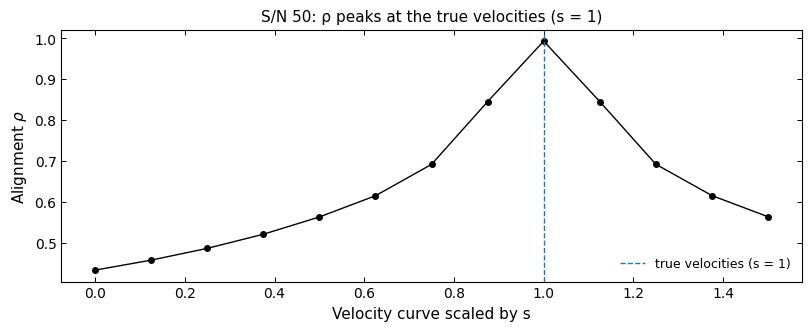

rho at s = 0: 0.434;  at s = 1: 0.9933;  maximum at s = 1.000


In [8]:
# Scale the trial velocities by s and rebuild: rho at each s
one_order = [[w] for w in waves], [[f] for f in fluxes]
scales = np.linspace(0, 1.5, 13)
rhos = [build_tiravel(*one_order, s * rv_true).rho for s in scales]

# Plot rho against s, with the truth (s = 1) marked
fig, ax = plt.subplots()
plot_curve(ax, scales, rhos, marker="o", ms=4)
ax.axvline(1.0, color=EXTRA_COLOR, ls="--", lw=1, label="true velocities (s = 1)")
ax.set_xlabel("Velocity curve scaled by s")
ax.set_ylabel(r"Alignment $\rho$")
ax.set_title(f"S/N {SNR}: ρ peaks at the true velocities (s = 1)")
ax.legend(loc="lower right")
plt.show()
# rho must peak at s = 1, the true velocities
print(f"rho at s = 0: {rhos[0]:.3f};  at s = 1: {rhos[np.argmin(np.abs(scales - 1))]:.4f};  "
      f"maximum at s = {scales[np.argmax(rhos)]:.3f}")
# Verify that the maximum is at s = 1
assert scales[np.argmax(rhos)] == 1.0

The correlation matrices at both ends (epochs sorted by true velocity): at the true velocities
every pair correlates almost perfectly; at zero velocity only epochs of similar velocity do.

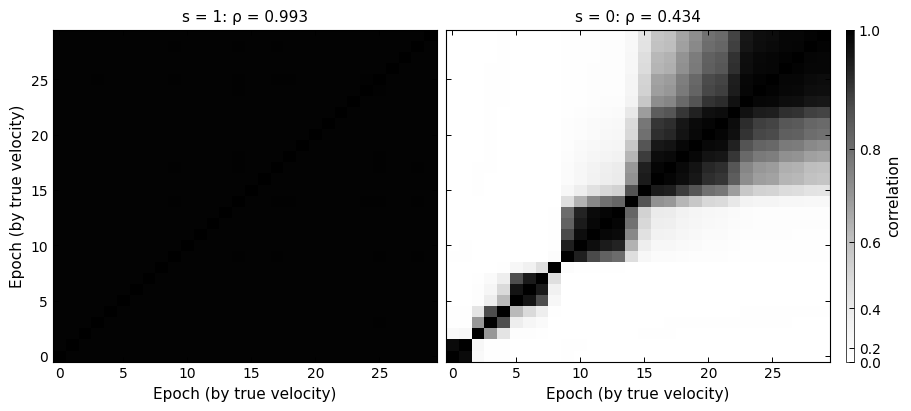

In [9]:
# Correlation matrices at the true velocities and at zero, epochs sorted by velocity
by_velocity = np.argsort(rv_true)
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, s in zip(axs, (1.0, 0.0)):
    built = build_tiravel(*one_order, s * rv_true)
    mesh = map_image(ax, np.arange(K), np.arange(K), built.correlation[np.ix_(by_velocity, by_velocity)])
    ax.set_title(f"s = {s:g}: ρ = {built.rho:.3f}")
    ax.set_xlabel("Epoch (by true velocity)")
axs[0].set_ylabel("Epoch (by true velocity)")
map_colorbar(mesh, "correlation", ax=axs)
plt.show()

**Only differences matter.** Adding a constant to every velocity aligns the spectra just as
well, but moves the template's rest frame, and the RVs measured against it, by that constant
([limitations § TIRAVEL](../../docs/limitations.md#tiravel)). `measure_rvs` below is the one-order CCF of notebook 03:
`resample_to_log_grid`, `lag_axis`, `ccf_order`, `combine_ccfs` (with one order, the CCF itself
up to rounding) and `measure_rv`.

In [10]:
# RVs of single-order epochs against a template: the one-order CCF of notebook 03
def measure_rvs(waves, fluxes, natives, t_wave, t_flux, dv=0.1, vel_bound=40, kept=None):
    '''RVs and their uncertainties (km/s) of single-order epochs against one template (UNICOR):
    each epoch on a log-λ grid of step dv (km/s), correlated over ±vel_bound (km/s); natives are
    the epochs' native pixel steps (km/s), which set the number of independent pixels, and kept
    the share of native noise a band-pass left in each (default 1: unfiltered).'''
    kept = [1.0] * len(waves) if kept is None else kept
    n_lags = int(round(vel_bound / dv))
    out = []
    for wave, flux, native, g in zip(waves, fluxes, natives, kept):
        w_log, f_log = resample_to_log_grid(wave, flux, dv)
        _, v = lag_axis([w_log], dv, n_lags)
        order = ccf_order(w_log, f_log, t_wave, t_flux, n_lags, dv_kms=dv, native_step_kms=native,
                          noise_fraction=g)
        combined = combine_ccfs(order.ccf[None, :], n_eff=np.array([order.n_eff]))
        rv = measure_rv(v, combined, order.n_eff)
        out.append((rv.rv, rv.erv))
    return np.array(out).T

# Native pixel steps of the epochs (km/s)
natives = [dv_from_wave(w) for w in waves]               # the simulated pixels are native
# Build the template with every velocity shifted by +5 km/s and measure RVs against it
offset = build_tiravel(*one_order, rv_true + 5.0)
rv_offset, _ = measure_rvs(waves, fluxes, natives, offset.grids[0], offset.template_flux[0])
# Alignment is unchanged, but the RVs shift by the same 5 km/s
print(f"rho with the true velocities:      {rho:.6f}")
print(f"rho with every velocity + 5 km/s:  {offset.rho:.6f}")
print(f"RVs against the offset template minus the truth: {np.mean(rv_offset - rv_true):+.3f} km/s on average")
# Verify: same rho, RVs moved by exactly the offset
assert np.isclose(offset.rho, rho, rtol=0, atol=1e-6)
assert abs(np.mean(rv_offset - rv_true) - 5.0) < 0.01

rho with the true velocities:      0.993292
rho with every velocity + 5 km/s:  0.993292
RVs against the offset template minus the truth: +5.000 km/s on average


**Is the template less noisy than the data?** The template is a weighted sum of normalised
spectra, so we compare shapes: subtract the best linear fit of the noiseless truth from one
aligned epoch and from the template. Averaging $K$ epochs with near-equal weights should cut the
noise by $\sqrt{n_\mathrm{eff}}$.

rms about the truth (continuum units): one epoch 0.0168 (median), template 0.0031
noise reduction 5.38, sqrt(n_eff) = 5.48
correlation with the truth: one epoch 0.9966, template 0.99989


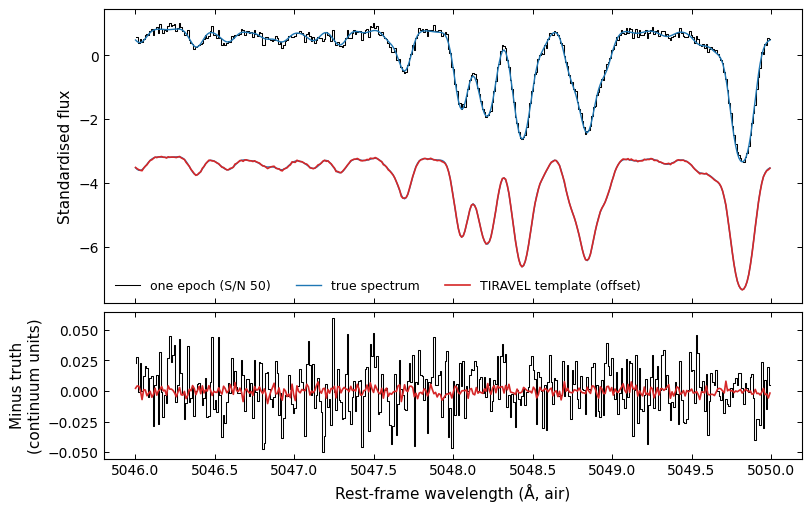

In [11]:
# Compare one aligned epoch with the template, in noise about the noiseless truth
epoch = normalized[1]                                     # epoch 1, at rest, on the grid
noise_epochs = np.median([residual(row, truth_on_grid).std() for row in normalized])
noise_template = residual(template, truth_on_grid).std()
# Noise of one epoch vs the template, and its expected reduction sqrt(n_eff)
print(f"rms about the truth (continuum units): one epoch {noise_epochs:.4f} (median), "
      f"template {noise_template:.4f}")
print(f"noise reduction {noise_epochs / noise_template:.2f}, "
      f"sqrt(n_eff) = {np.sqrt(align['n_eff']):.2f}")
print(f"correlation with the truth: one epoch {np.corrcoef(epoch, truth_on_grid)[0, 1]:.4f}, "
      f"template {np.corrcoef(template, truth_on_grid)[0, 1]:.5f}")
# The noise reduction must match sqrt(n_eff)
assert np.isclose(noise_epochs / noise_template, np.sqrt(align["n_eff"]), rtol=0.05)

# Plot a zoom: epoch, truth and template, with the residuals below
zoom = (grid > 5046) & (grid < 5050)
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(8, 5), height_ratios=[2, 1])
plot_data(top, grid[zoom], standardise(epoch)[zoom], label="one epoch (S/N 50)")
plot_extra(top, grid[zoom], standardise(truth_on_grid)[zoom], label="true spectrum")
plot_extra(top, grid[zoom], standardise(truth_on_grid)[zoom] - 4)
plot_model(top, grid[zoom], standardise(template)[zoom] - 4, label="TIRAVEL template (offset)")
top.set_ylabel("Standardised flux")
top.legend(loc="lower left", ncols=3)
plot_data(bottom, grid[zoom], residual(epoch, truth_on_grid)[zoom])
plot_model(bottom, grid[zoom], residual(template, truth_on_grid)[zoom])
bottom.set_xlabel("Rest-frame wavelength (Å, air)")
bottom.set_ylabel("Minus truth\n(continuum units)")
plt.show()

**And the RVs?** Measured against the TIRAVEL template and against the noiseless true one. If the
uncertainties are right, the rms about the true velocities should match the median uncertainty.

In [12]:
# Measure the RVs against the true and the TIRAVEL template and compare their scatter
# with the formal uncertainties
for name, t_wave, t_flux in [("true template", truth_wave, truth_flux),
                             ("TIRAVEL template", grid, template)]:
    rv, erv = measure_rvs(waves, fluxes, natives, t_wave, t_flux)
    rms, median_err = np.std(rv - rv_true), np.median(erv)
    print(f"{name:16s}: rms about the truth {rms * 1e3:.1f} m/s, "
          f"median uncertainty {median_err * 1e3:.1f} m/s, ratio {rms / median_err:.2f}")
    assert 0.7 < rms / median_err < 1.3

true template   : rms about the truth 3.1 m/s, median uncertainty 3.6 m/s, ratio 0.86
TIRAVEL template: rms about the truth 3.5 m/s, median uncertainty 3.6 m/s, ratio 0.99


Both agree with the truth within their errors: the template carries about $1/\sqrt{30}$ of one
epoch's noise, so it costs little precision against a perfect noiseless one.

**How S/N sets ρ and the template.** At three signal-to-noise ratios, $1 - \rho$ scales as
$(S/N)^{-2}$ and the template's noise as $(S/N)^{-1}$, always about $\sqrt{30}$ below one
epoch's (one seed for all three: the same noise pattern, scaled, so the ratio repeats exactly).

In [13]:
# Repeat the build at three S/N: rho, and the noise of one epoch vs the template
print(" S/N    rho    (1-rho)(S/N)^2   noise: one epoch   template   ratio")
for snr in (25, 50, 100):
    sweep_waves, sweep_fluxes = epochs(snr)
    built = build_tiravel([[w] for w in sweep_waves], [[f] for f in sweep_fluxes], rv_true)
# Noise about the truth: median over epochs vs the template
    one = np.median([residual(row, truth_on_grid).std() for row in built.aligned[0]])
    coadded = residual(built.template_flux[0], truth_on_grid).std()
    print(f"{snr:4d}  {built.rho:.4f}  {(1 - built.rho) * snr**2:10.1f}  "
          f"{one:16.4f}  {coadded:9.4f}  {one / coadded:6.2f}")

 S/N    rho    (1-rho)(S/N)^2   noise: one epoch   template   ratio


  25  0.9737        16.4            0.0336     0.0062    5.38


  50  0.9933        16.8            0.0168     0.0031    5.38
 100  0.9983        16.9            0.0084     0.0016    5.38


## 3. Real data: HARPS spectra of TOI-193

TOI-193 (LTT 9779) is a quiet, slowly rotating Sun-like star, for which a PHOENIX model is a good
template. So this is a validation: TIRAVEL should rebuild a template like the library one from
the data alone.

The HARPS loader reads each archive file over the recommended 4990-5090 Å window. The archive
grid is a resampling of the detector pixels, so the record also carries the native step, which
the CCF's uncertainty counts ([instruments § HARPS](../../docs/instruments.md#harps),
[conventions § native sampling](../../docs/conventions.md#native-sampling-and-the-number-of-independent-pixels)).

In [14]:
# Load the TOI-193 HARPS spectra over the recommended window
harps = instruments.get("HARPS")
paths = sorted(pathlib.Path("../data/TOI193").glob("*.fits"))
records = [harps.load(str(path), min_wv=4990, max_wv=5090) for path in paths]
first = records[0]
# Summarise the data: frame, barycentric correction, archive vs native step
print(f"{len(records)} spectra over {np.ptp([r.time for r in records]):.1f} days; frame "
      f"{first.wavelength_frame}, SPECSYS {first.specsys}, bcv {first.bcv} km/s")
print(f"archive step {dv_from_wave(first.wave[0]):.3f} km/s (mid-window), "
      f"native step {first.native_step_kms[0]:.3f} km/s")

32 spectra over 54.1 days; frame air, SPECSYS BARYCENT, bcv 0.0 km/s
archive step 0.595 km/s (mid-window), native step 0.609 km/s


The recommended HARPS preprocessing (notebook 03), atom by atom: `trim_margins`,
`resample_to_linear_grid`, `remove_cosmics` and `bandpass` (no taper: fading the ends biases the CCF); what each
does and why in this order: [conventions § preprocessing order](../../docs/conventions.md#preprocessing-order).
`coarsest_native_step` keeps the native step through every resampling. The spectra are
barycentric already (`bcv` = 0); the correction is applied anyway, as for any product.

In [15]:
# The recommended HARPS preprocessing settings
pre = harps.recommended.preprocess
print(pre)

# The recommended preprocessing chain on one order
def preprocess(wave, flux):
    '''The recommended chain on one order: wavelengths (Å) and filtered flux.'''
    wave, flux = trim_margins(wave, flux, n_left=pre["n_trim"], n_right=pre["n_trim"],
                              clean_margins=pre["clean_margins"], remove_nans=pre["remove_nans"])
    wave, flux = resample_to_linear_grid(wave, flux, pre["delta"])
    flux = remove_cosmics(wave, flux, sigma_upper=pre["cosmic_sigma"])
    flux = bandpass(wave, flux, pre["continuum_scale_kms"], pre["noise_scale_kms"], order=1)
    return wave, flux

# Apply it to every spectrum: barycentric correction, native step, filtering
h_waves, h_fluxes, h_natives, h_kept = [], [], [], []
for rec in records:
    wave = doppler_shift_wave(rec.wave[0], rec.bcv, convention="cz")
    native = coarsest_native_step(rec.native_step_kms[0], rec.wave[0])
    wave, flux = preprocess(wave, rec.flux[0])
    h_waves.append(wave)
    h_fluxes.append(flux)
    h_natives.append(coarsest_native_step(native, wave))
    # The share of the native noise the band-pass kept: it sets the error bars
    h_kept.append(filtered_noise_fraction(wave, pre["continuum_scale_kms"], pre["noise_scale_kms"],
                                          h_natives[-1]))
# Observation times (days)
h_times = np.array([rec.time for rec in records])
print(f"{h_waves[0].size} pixels of {np.diff(h_waves[0])[0]:.4f} Å; native step {h_natives[0]:.3f} km/s")

{'n_trim': 10, 'clean_margins': True, 'remove_nans': True, 'delta': 0.5, 'cosmic_sigma': 3, 'continuum_scale_kms': 2000.0, 'noise_scale_kms': 4.0}
19956 pixels of 0.0050 Å; native step 0.609 km/s


A library template near this star's published parameters (5500 K, log g 4.5, solar),
broadened for a slow rotation and the HARPS resolving power, and preprocessed like the data.
HARPS is in **air**, so `air=True` ([conventions § air and vacuum](../../docs/conventions.md#air-and-vacuum-wavelengths)).
As in notebook 03, `broaden` applies each kernel on a log-λ grid at the finest velocity step and
resamples back.

In [16]:
# Apply a broadening kernel on a log-λ grid, then resample back to wave
def broaden(wave, flux, kernel):
    '''kernel(flux, dv) applied on a log-λ grid at the finest velocity step of wave (km/s).'''
    dv = C_KMS * np.min(np.diff(wave) / wave[:-1])
    grid, _ = log_lambda_grid(wave[0], wave[-1], dv)
    return resample(grid, kernel(resample(wave, flux, grid, kind="cubic"), dv), wave, kind="cubic")

# PHOENIX template: broadened to the star's rotation and the HARPS resolution
def library_template(air):
    '''PHOENIX 5500 K, log g 4.5, broadened (vsini 1.5 km/s, HARPS R) and preprocessed.'''
    wave, flux = phoenix_spectrum(5500, 4.5, wave_range=(4960, 5120), air=air)
    flux = broaden(wave, flux, lambda f, dv: broaden_rotational(f, dv, 1.5, 0.5))
    flux = broaden(wave, flux,
                   lambda f, dv: broaden_gaussian(f, dv, C_KMS / harps.instrument.resolving_power))
    return preprocess(wave, flux)

# RVs against the library template (air, as the data)
lib_wave, lib_flux = library_template(air=True)
rv_library, _ = measure_rvs(h_waves, h_fluxes, h_natives, lib_wave, lib_flux, vel_bound=150, kept=h_kept)
print(f"mean RV = {rv_library.mean():.3f} km/s, rms = {rv_library.std() * 1e3:.1f} m/s")

mean RV = -10.436 km/s, rms = 14.2 m/s


The same template left in vacuum wavelengths shifts every RV by the air-vacuum difference:

In [17]:
# The same template in vacuum wavelengths gives wrong RVs
rv_vacuum, _ = measure_rvs(h_waves, h_fluxes, h_natives, *library_template(air=False),
                           vel_bound=150, kept=h_kept)
print(f"mean RV with a vacuum template: {rv_vacuum.mean():.3f} km/s "
      f"(off by {(rv_library - rv_vacuum).mean():.2f} km/s)")

mean RV with a vacuum template: -94.013 km/s (off by 83.58 km/s)


Now TIRAVEL, at the library velocities. SPARTA does not optimise ρ over the velocities
([limitations § TIRAVEL](../../docs/limitations.md#tiravel)), hence the bootstrap: rough RVs from any template, a template
from the data, then RVs again.

rho = 0.9973; effective number of contributing epochs = 32.0 of 32


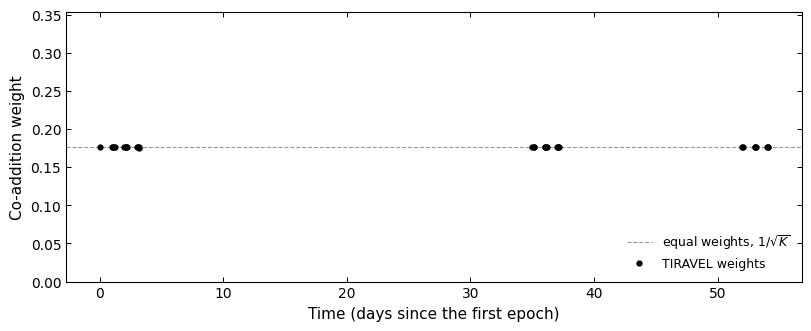

In [18]:
# Build the TIRAVEL template from the data at the library velocities
tir_h = build_tiravel([[w] for w in h_waves], [[f] for f in h_fluxes], rv_library)
n = len(h_waves)
print(f"rho = {tir_h.rho:.4f}; effective number of contributing epochs = "
      f"{tir_h.diagnostics['n_eff']:.1f} of {n}")
# Every epoch must contribute with a positive weight
assert np.all(tir_h.weights > 0)

# Plot the co-addition weight of each epoch against time
fig, ax = plt.subplots()
ax.axhline(1 / np.sqrt(n), color=GREY, lw=0.8, ls="--", label=r"equal weights, $1/\sqrt{K}$")
plot_points(ax, h_times - h_times.min(), tir_h.weights, label="TIRAVEL weights")
ax.set_ylim(0, 2 / np.sqrt(n))
ax.set_xlabel("Time (days since the first epoch)")
ax.set_ylabel("Co-addition weight")
ax.legend(loc="lower right")
plt.show()

Near-equal weights: every epoch contributes, and none anti-correlates with the rest (a negative
weight would flag a bad spectrum or a wrong velocity). Do the two templates agree?

correlation of the TIRAVEL and library templates: 0.897


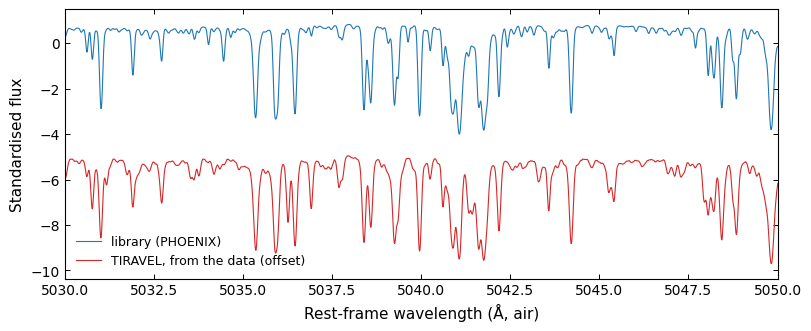

In [19]:
# Put both templates on one grid and standardise them
compare = np.linspace(5010, 5070, 6000)                 # Å, one grid for both templates
lib_line = standardise(np.interp(compare, lib_wave, lib_flux))
tir_line = standardise(np.interp(compare, tir_h.grids[0], tir_h.template_flux[0]))
# Their correlation measures how well TIRAVEL rebuilt the library template
agreement = np.corrcoef(lib_line, tir_line)[0, 1]
print(f"correlation of the TIRAVEL and library templates: {agreement:.3f}")
# The templates must agree
assert agreement > 0.85

# Plot the two templates on the same lines (TIRAVEL offset below)
fig, ax = plt.subplots()
plot_extra(ax, compare, lib_line, lw=0.8, label="library (PHOENIX)")
plot_model(ax, compare, tir_line - 6, lw=0.8, label="TIRAVEL, from the data (offset)")
ax.set_xlim(5030, 5050)
ax.set_xlabel("Rest-frame wavelength (Å, air)")
ax.set_ylabel("Standardised flux")
ax.legend(loc="lower left")
plt.show()

The same lines, at the same positions. The correlation is lower than in the simulation, where
the reference was the exact noiseless spectrum; here it is only a model of the star. The RVs
against the TIRAVEL template:

TIRAVEL - library RVs: mean +0.00 m/s, rms 2.4 m/s (the RV rms itself is 14.2 m/s)


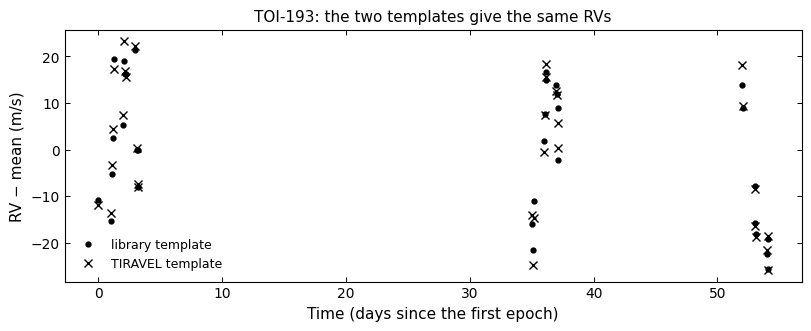

In [20]:
# RVs against the TIRAVEL template
rv_tiravel, erv_tiravel = measure_rvs(h_waves, h_fluxes, h_natives, tir_h.grids[0],
                                      tir_h.template_flux[0], vel_bound=150, kept=h_kept)
# How much they differ from the library-template RVs
diff = rv_tiravel - rv_library
print(f"TIRAVEL - library RVs: mean {diff.mean() * 1e3:+.2f} m/s, rms {diff.std() * 1e3:.1f} m/s "
      f"(the RV rms itself is {rv_library.std() * 1e3:.1f} m/s)")
# The difference must be small next to the RV scatter itself
assert diff.std() < rv_library.std() / 3

# Plot both RV series, mean removed (m/s)
by_time = np.argsort(h_times)
t = (h_times - h_times.min())[by_time]
fig, ax = plt.subplots()
plot_points(ax, t, (rv_library - rv_library.mean())[by_time] * 1e3, label="library template")
plot_points(ax, t, (rv_tiravel - rv_tiravel.mean())[by_time] * 1e3, fmt="x", ms=6,
            label="TIRAVEL template")
ax.set_xlabel("Time (days since the first epoch)")
ax.set_ylabel("RV − mean (m/s)")
ax.set_title("TOI-193: the two templates give the same RVs")
ax.legend()
plt.show()

The mean difference is ~0 because the TIRAVEL template inherits the zero point of the library
velocities it was built from.

## 4. The same numbers with the objects

`TIRAVEL.build_template`, `Observations.preprocess`, `Observations.build_tiravel_template` and
`calc_rv_against_template` chain the same functions: ρ, weights, template and RVs are identical,
bit for bit ([`howto/03_template_from_data`](../howto/03_template_from_data.ipynb) is the short recipe):

In [21]:
from sparta import TIRAVEL, Observations

# Object path: the same simulated build with TIRAVEL.build_template
simulated = Observations(survey="SIMULATED", simulation=sim)
built = TIRAVEL().build_template(simulated.spec_list, rv_true)
# Verify the objects give the same rho, weights and template
assert built.rho == rho and np.array_equal(built.weights, weights)
assert np.array_equal(built.template.model.wv[0], grid)
assert np.array_equal(built.template.model.sp[0], template)

# Real HARPS data: preprocess, build the template and measure RVs with Observations
obs = Observations(survey="HARPS", target_visits_lib="../data/TOI193/", min_wv=4990, max_wv=5090)
obs.preprocess(**pre)
obs.build_tiravel_template(rv_library)
# Verify the same numbers as the atoms, bit for bit
assert obs.tiravel.rho == tir_h.rho and np.array_equal(obs.tiravel.weights, tir_h.weights)
assert np.array_equal(obs.tiravel_template.model.wv[0], tir_h.grids[0])
assert np.array_equal(obs.tiravel_template.model.sp[0], tir_h.template_flux[0])
# RVs against the TIRAVEL template
obs.calc_rv_against_template(obs.tiravel_template, dv=0.1, vel_bound=150)
# The RVs must match the atoms' too
assert np.array_equal(obs.vels, rv_tiravel) and np.array_equal(obs.evels, erv_tiravel)
print("TIRAVEL and Observations: rho, weights, template and RVs identical to the atoms'")

TIRAVEL and Observations: rho, weights, template and RVs identical to the atoms'


## Summary / next

- TIRAVEL is four steps on plain arrays: `common_grid` and `align_spectra`, `normalize_rows`,
  `correlation_matrix` and `alignment` (ρ, the weights), `coadd`; `build_tiravel` chains them.
- ρ is the alignment diluted by the noise ($1 - \rho \propto (S/N)^{-2}$); it peaks at the true
  velocities, and only their differences matter.
- The template's noise is about $\sqrt{n_\mathrm{eff}}$ below one epoch's (5.4 for 30 epochs).
- On simulated data and on HARPS TOI-193 it reproduces the reference template and its RVs.

Status, diagnostics and the development plan: [docs/tiravel.md](../../docs/tiravel.md).

**Next:** [`06_pdc`](06_pdc.ipynb): periodograms of an RV series, GLS and PDC.